---
title: "House Price Prediction"
description: " "
date: 2023-04-20
categories: [Machine Learning, Regression]
image: images/house-price.jpg
---

<ol class="breadcrumb">
  <li class="breadcrumb-item"><a href="../../index.qmd">Home</a></li>
  <li class="breadcrumb-item"><a href="../ai/index.qmd">Artificial Intelligence Projects</a></li>
  <li class="breadcrumb-item active">House Price Prediction</li>
</ol>

## Overview

This notebook investigates the use of machine learning model, namely linear regression, to predict house price using the following dataset.

[<i class="bi bi-download"></i> Download Dataset (.csv)](data/house_price.csv){.btn .btn-secondary role="button" download="" target="_blank}

The analysis covers these main steps:

1. Data preprocessing and Exploratory Data Analysis (EDA)
2. Statistical analysis for feature selection
3. Model training
4. Model evaluation

The primary objective is to understand how to perform end-to-end machine learning process. 

## Install and Import Packages

In [ ]:
%pip install --upgrade -q matplotlib numpy pandas scikit-learn scipy seaborn

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

## Load Dataset

In [3]:
df = pd.read_csv('data/house_price.csv')
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## Data Preprocessing and EDA

### Data Preprocessing Phase 1

First, let's take a look at the dataset overview.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

Based on the output above, here are some informations about the dataset.
- The dataset has 1460 rows and 81 columns.
- The target variable is 'SalePrice'.
- The features consist of both numerical and categorical features.
- Notice that there are some features with missing values.

Let's also see the distribution of the target variable (SalePrice).

<Axes: ylabel='Frequency'>

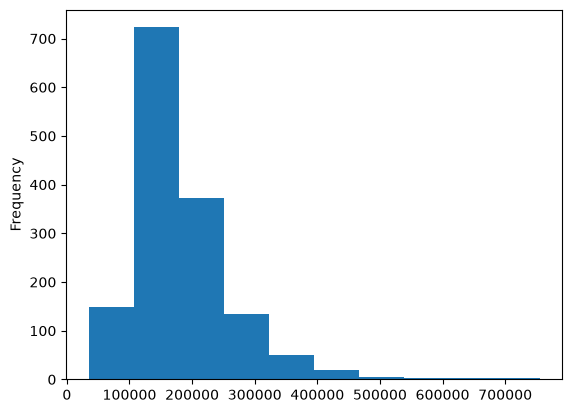

In [5]:
df['SalePrice'].plot(kind='hist')

#### Dropping Unnecessary Columns

In [6]:
# drop column 'Id' because it is same as an index
try:
    df = df.drop(columns=['Id'])
    print('Successfully Removed Column Id.')
except KeyError:
    print('Column Id Not Found or Has Been Removed.')

Successfully Removed Column Id.


#### Checking dan Dropping Duplicated Rows

In [7]:
# check and drop duplicated rows (if exist)
total_duplicates = df.duplicated().sum()
print(f'Total duplicated rows: {total_duplicates}')
if total_duplicates:
    df = df.drop_duplicates()
    print('All duplicated rows has been removed.')
else:
    print('No duplicated rows need to be dropped.')

Total duplicated rows: 0
No duplicated rows need to be dropped.


Now, let's focus on identifying which features have missing values and each missing values counts.

#### Checking Missing Values

In [8]:
check_missing_values_series = df.isna().sum().sort_values()
missing_values_series = check_missing_values_series[check_missing_values_series > 0]

missing_values_columns = missing_values_series.index.tolist()

missing_dtypes = [str(df[column].dtypes) for column in missing_values_columns]
missing_dtypes_series = pd.Series(data=missing_dtypes, index=missing_values_columns)

missing_unique = [df[column].unique().tolist() for column in missing_values_columns]
missing_unique_series = pd.Series(data=missing_unique, index=missing_values_columns)

missing_values_df = pd.concat([missing_values_series, missing_dtypes_series, missing_unique_series], axis=1)
missing_values_df = missing_values_df.rename(columns={0: 'Missing Values Counts', 1: 'Dtype', 2: 'Unique Values'})
print(missing_values_df)
print()
print(f'Total Columns with Missing Values: {len(missing_values_df)}')

              Missing Values Counts    Dtype  \
Electrical                        1      str   
MasVnrArea                        8  float64   
BsmtFinType1                     37      str   
BsmtCond                         37      str   
BsmtQual                         37      str   
BsmtFinType2                     38      str   
BsmtExposure                     38      str   
GarageType                       81      str   
GarageCond                       81      str   
GarageFinish                     81      str   
GarageQual                       81      str   
GarageYrBlt                      81  float64   
LotFrontage                     259  float64   
FireplaceQu                     690      str   
MasVnrType                      872      str   
Fence                          1179      str   
Alley                          1369      str   
MiscFeature                    1406      str   
PoolQC                         1453      str   

                                       

Based on the output above, there are 19 columns with missing values.

Here are the strategies for handling those missing values.

- **Drop** the **GarageYrBlt** column. From a logical and temporal standpoint, the construction year of a garage functions as a close linear approximation of the primary structure's construction year (YearBuilt), as residential garages are typically built concurrently with the main house. Imputing the missing values (which mathematically represent the absence of a garage) with a continuous year would introduce noise. Therefore, treating GarageYrBlt as a redundant temporal proxy and dropping it is a mathematically sound decision, as the variance of the property's age is already rigorously accounted for by YearBuilt.

- **Impute** the **numerical features** (MasVnrArea, LotFrontage) **using the median** to mitigate the influence of extreme values. 

- **Impute** the **categorical features** **using a constant value ('None')** since the missing values systematically represent the absence of a specific house facility (e.g., no fence, no alley), making 'None' a structurally meaningful category. 

- The only **exception** is the **Electrical** feature, where the single missing value is **imputed using the mode (most frequent value)**, assuming the missing entry is a data entry omission rather than the complete absence of an electrical system.

#### Handling Missing Values

##### Train-Test Split

Before handling the missing values, split the the data into train and test set. Here, we are using 80:20 ratio for the train and test set. 

We must split our data first, to avoid data leakage

In [9]:
from sklearn.model_selection import train_test_split

# drop GarageYrBlt
try:
    df = df.drop(columns=['GarageYrBlt'])
    try:
        missing_values_columns.remove('GarageYrBlt')
    except:
        pass
    print('Successfully Removed Column GarageYrBlt.')
except KeyError:
    print('Column GarageYrBlt Not Found or Has Been Removed.')

# separate the target variable
target = 'SalePrice'
y = df[target].values

X_df = df.drop(columns=[target])

# split the data into train and test set
X_train_df, X_test_df, y_train, y_test = train_test_split(X_df, y, test_size=0.2, random_state=42)
print(f'X_train_df shape: {X_train_df.shape}')
print(f'X_test_df shape: {X_test_df.shape}')
print(f'y_train shape: {y_train.shape}')
print(f'y_test shape: {y_test.shape}')

Successfully Removed Column GarageYrBlt.
X_train_df shape: (1168, 78)
X_test_df shape: (292, 78)
y_train shape: (1168,)
y_test shape: (292,)


Divide the data into the column without missing values, column with numerical missing values, column with categorical missing values, and column with special treatment categorical missing values.

In [10]:
missing_num_columns = ['MasVnrArea', 'LotFrontage']
missing_special_cat_columns = ['Electrical']
missing_cat_columns = set(missing_values_columns.copy())
remove_from_missing_cat = set(missing_num_columns + missing_special_cat_columns)
missing_cat_columns = list(missing_cat_columns - remove_from_missing_cat)

not_missing_columns = df.drop(columns=missing_values_columns+[target]).columns.tolist()

X_train_not_missing = X_train_df[not_missing_columns].values
X_test_not_missing = X_test_df[not_missing_columns].values

X_train_missing_num = X_train_df[missing_num_columns].values
X_test_missing_num = X_test_df[missing_num_columns].values

X_train_missing_cat = X_train_df[missing_cat_columns].values
X_test_missing_cat = X_test_df[missing_cat_columns].values

X_train_missing_special_cat = X_train_df[missing_special_cat_columns].values
X_test_missing_special_cat = X_test_df[missing_special_cat_columns].values

print(f'X_train_not_missing shape: {X_train_not_missing.shape}')
print(f'X_test_not_missing shape: {X_test_not_missing.shape}')
print(f'X_train_missing_num shape: {X_train_missing_num.shape}')
print(f'X_test_missing_num shape: {X_test_missing_num.shape}')
print(f'X_train_missing_cat shape: {X_train_missing_cat.shape}')
print(f'X_test_missing_cat shape: {X_test_missing_cat.shape}')
print(f'X_train_missing_special_cat shape: {X_train_missing_special_cat.shape}')
print(f'X_test_missing_special_cat shape: {X_test_missing_special_cat.shape}')


X_train_not_missing shape: (1168, 60)
X_test_not_missing shape: (292, 60)
X_train_missing_num shape: (1168, 2)
X_test_missing_num shape: (292, 2)
X_train_missing_cat shape: (1168, 15)
X_test_missing_cat shape: (292, 15)
X_train_missing_special_cat shape: (1168, 1)
X_test_missing_special_cat shape: (292, 1)


##### Using SimpleImputer

Then, we can do the imputation using SimpleImputer from the scikit-learn.

In [11]:
from sklearn.impute import SimpleImputer

# create each imputer instance
num_imputer = SimpleImputer(strategy='median')
cat_imputer = SimpleImputer(strategy='constant', fill_value='None')
special_cat_imputer = SimpleImputer(strategy='most_frequent')

# fit-transform to the missing train set and only transform to the missing test set to avoid data leakage
X_train_imputed_num = num_imputer.fit_transform(X_train_missing_num)
X_test_imputed_num = num_imputer.transform(X_test_missing_num)

X_train_imputed_cat = cat_imputer.fit_transform(X_train_missing_cat)
X_test_imputed_cat = cat_imputer.transform(X_test_missing_cat)

X_train_imputed_special_cat = special_cat_imputer.fit_transform(X_train_missing_special_cat)
X_test_imputed_special_cat = special_cat_imputer.transform(X_test_missing_special_cat)

# concatenate all train and test set
X_train_imputed = np.concatenate((X_train_not_missing, X_train_imputed_num, X_train_imputed_cat, X_train_imputed_special_cat), axis=1)
X_test_imputed = np.concatenate((X_test_not_missing, X_test_imputed_num, X_test_imputed_cat, X_test_imputed_special_cat), axis=1)

print(f'X_train_imputed shape: {X_train_imputed.shape}')
print(f'X_test_imputed shape: {X_test_imputed.shape}')

X_train_imputed shape: (1168, 78)
X_test_imputed shape: (292, 78)


In [12]:
# convert X_train_imputed and X_test_imputed to DataFrame
current_all_columns = not_missing_columns + missing_num_columns + missing_cat_columns + missing_special_cat_columns
X_train_imputed_df = pd.DataFrame(data=X_train_imputed, columns=current_all_columns)
X_test_imputed_df = pd.DataFrame(data=X_test_imputed, columns=current_all_columns)

In [13]:
X_train_imputed_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1168 entries, 0 to 1167
Data columns (total 78 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   MSSubClass     1168 non-null   object
 1   MSZoning       1168 non-null   str   
 2   LotArea        1168 non-null   object
 3   Street         1168 non-null   str   
 4   LotShape       1168 non-null   str   
 5   LandContour    1168 non-null   str   
 6   Utilities      1168 non-null   str   
 7   LotConfig      1168 non-null   str   
 8   LandSlope      1168 non-null   str   
 9   Neighborhood   1168 non-null   str   
 10  Condition1     1168 non-null   str   
 11  Condition2     1168 non-null   str   
 12  BldgType       1168 non-null   str   
 13  HouseStyle     1168 non-null   str   
 14  OverallQual    1168 non-null   object
 15  OverallCond    1168 non-null   object
 16  YearBuilt      1168 non-null   object
 17  YearRemodAdd   1168 non-null   object
 18  RoofStyle      1168 non-null   str   
 

In [14]:
X_test_imputed_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 292 entries, 0 to 291
Data columns (total 78 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   MSSubClass     292 non-null    object
 1   MSZoning       292 non-null    str   
 2   LotArea        292 non-null    object
 3   Street         292 non-null    str   
 4   LotShape       292 non-null    str   
 5   LandContour    292 non-null    str   
 6   Utilities      292 non-null    str   
 7   LotConfig      292 non-null    str   
 8   LandSlope      292 non-null    str   
 9   Neighborhood   292 non-null    str   
 10  Condition1     292 non-null    str   
 11  Condition2     292 non-null    str   
 12  BldgType       292 non-null    str   
 13  HouseStyle     292 non-null    str   
 14  OverallQual    292 non-null    object
 15  OverallCond    292 non-null    object
 16  YearBuilt      292 non-null    object
 17  YearRemodAdd   292 non-null    object
 18  RoofStyle      292 non-null    str   
 19

For the next exploratory data analysis, it is conducted exclusively on the Training Set. The Test Set remains completely untouched and unseen, acting as pure out-of-sample data to ensure an unbiased evaluation of the final regression model.

#### Feature Engineering

Now, we are going to do some feature engineering. Before that, let's take a look at the unique values and the mode of current each column.

In [15]:
print('-----Unique Values and Mode in Each Column-----\n\n')
for column in current_all_columns:
    print(f'Unique Values in {column}:')
    print(X_train_imputed_df[column].unique().tolist())
    print()
    print(f'Mode: {X_train_imputed_df[column].mode()[0]}')
    print('='*50)

-----Unique Values and Mode in Each Column-----


Unique Values in MSSubClass:
[20, 60, 30, 50, 85, 80, 45, 90, 160, 40, 190, 75, 120, 70, 180]

Mode: 20
Unique Values in MSZoning:
['RL', 'RM', 'FV', 'RH', 'C (all)']

Mode: RL
Unique Values in LotArea:
[8400, 7837, 8777, 7200, 5000, 9800, 11911, 5436, 12090, 9158, 13400, 11880, 13600, 9600, 8068, 21000, 8235, 7950, 12416, 10594, 11643, 6240, 10237, 10083, 4251, 17500, 8544, 9541, 12144, 5604, 10240, 9991, 7252, 12160, 9353, 7018, 13284, 6600, 7060, 3604, 8892, 5362, 4456, 11639, 8000, 7082, 14054, 11003, 11846, 8520, 11029, 10246, 13500, 13693, 3842, 11200, 10475, 12772, 10205, 6342, 7500, 10437, 12046, 10762, 9375, 29959, 9204, 3182, 10140, 9060, 12342, 9750, 11767, 8121, 7134, 9056, 9790, 7800, 16560, 11751, 1680, 10603, 9187, 32463, 11207, 14112, 13710, 9554, 8712, 8100, 11143, 9786, 6000, 21750, 4928, 11694, 11409, 14948, 2500, 11249, 12358, 8029, 46589, 8525, 8250, 10500, 25000, 10800, 5001, 10186, 5330, 9591, 7931, 20896, 9560, 1

From the output above, we can do some feature engineering as follows.

- **Create** new numerical feature **HouseAge** and **AgeAftRemod** where **HouseAge = YrSold - YearBuilt** and **AgeAftRemod = YrSold - YearRemodAdd**. Then, **drop YrSold, YearBuilt, and YearRemodAdd**.

- **Create** new numerical feature **TotalBath** where **TotalBath = BsmtFullBath + 0.5\*BsmtHalfBath + FullBath + 0.5\*HalfBath**. Then, **drop BsmtFullBath, BsmtHalfBath, FullBath and HalfBath**. Half baths are assigned a constant utility weight of $0.5$ to preserve the exact functional utility and economic weight of the property's sanitation facilities.

- **Create** new numerical feature **TotalPorchSF** where **TotalPorchSF = WoodDeckSF + OpenPorchSF + EnclosedPorch + 3SsnPorch + ScreenPorch**. Then, **drop WoodDeckSF, OpenPorchSF, EnclosedPorch, 3SsnPorch, and ScreenPorch**. This is based on the  inspections that reveal high sparsity (excessive zero values) across these individual features because properties rarely possess all five porch types simultaneously.

Also, we can make some hypotheses.

- The feature **TotalBsmtSF** is **hypothesized** to be a perfect linear combination of its sub-components: **TotalBsmtSF = BsmtFinSF1 + BsmtFinSF2 + BsmtUnfSF**. A program will be executed to verify if the equation holds true across 100% of the rows. **If this deterministic relationship is validated, the three sub-components will be systematically dropped** to eliminate redundancy and prevent multicollinearity.

- The feature **GrLivArea** is **hypothesized** to be a perfect linear combination of its sub-components: **GrLivArea = 1stFlrSF + 2ndFlrSF + LowQualFinSF**. A program will be executed to verify if the equation holds true across 100% of the rows. **If this deterministic relationship is validated, the three sub-components will be systematically dropped** to eliminate redundancy and prevent multicollinearity.

In [16]:
# execute the plan

# HouseAge and AgeAftRemod
X_train_imputed_df['HouseAge'] = X_train_imputed_df['YrSold'] - X_train_imputed_df['YearBuilt']
X_train_imputed_df['AgeAftRemod'] = X_train_imputed_df['YrSold'] - X_train_imputed_df['YearRemodAdd']

X_test_imputed_df['HouseAge'] = X_test_imputed_df['YrSold'] - X_test_imputed_df['YearBuilt']
X_test_imputed_df['AgeAftRemod'] = X_test_imputed_df['YrSold'] - X_test_imputed_df['YearRemodAdd']


# TotalBath
X_train_imputed_df['TotalBath'] = (X_train_imputed_df['BsmtFullBath'] + 0.5*X_train_imputed_df['BsmtHalfBath'] + X_train_imputed_df['FullBath'] 
                                   + 0.5*X_train_imputed_df['HalfBath'])
X_test_imputed_df['TotalBath'] = (X_test_imputed_df['BsmtFullBath'] + 0.5*X_test_imputed_df['BsmtHalfBath'] + X_test_imputed_df['FullBath'] 
                                  + 0.5*X_test_imputed_df['HalfBath'])


# TotalPorchSF
X_train_imputed_df['TotalPorchSF'] = (X_train_imputed_df['WoodDeckSF'] + X_train_imputed_df['OpenPorchSF'] + X_train_imputed_df['EnclosedPorch'] 
                                      + X_train_imputed_df['3SsnPorch'] + X_train_imputed_df['ScreenPorch'])
X_test_imputed_df['TotalPorchSF'] = (X_test_imputed_df['WoodDeckSF'] + X_test_imputed_df['OpenPorchSF'] + X_test_imputed_df['EnclosedPorch'] 
                                      + X_test_imputed_df['3SsnPorch'] + X_test_imputed_df['ScreenPorch'])


X_train_imputed_df = X_train_imputed_df.drop(columns=['YrSold', 'YearBuilt', 'YearRemodAdd', 'BsmtFullBath', 'BsmtHalfBath',
                                                       'FullBath', 'HalfBath', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', 
                                                       '3SsnPorch', 'ScreenPorch'])
X_test_imputed_df = X_test_imputed_df.drop(columns=['YrSold', 'YearBuilt', 'YearRemodAdd', 'BsmtFullBath', 'BsmtHalfBath',
                                                     'FullBath', 'HalfBath', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', 
                                                     '3SsnPorch', 'ScreenPorch'])


# TotalBsmtSF
basement_check = (X_train_imputed_df['TotalBsmtSF'] == (X_train_imputed_df['BsmtFinSF1'] + X_train_imputed_df['BsmtFinSF2'] + X_train_imputed_df['BsmtUnfSF'])).all()
if basement_check:
    X_train_imputed_df = X_train_imputed_df.drop(columns=['BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF'])
    X_test_imputed_df = X_test_imputed_df.drop(columns=['BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF'])


# GrLivArea
grliv_check = (X_train_imputed_df['GrLivArea'] == (X_train_imputed_df['1stFlrSF'] + X_train_imputed_df['2ndFlrSF'] + X_train_imputed_df['LowQualFinSF'])).all()
if grliv_check:
    X_train_imputed_df = X_train_imputed_df.drop(columns=['1stFlrSF', '2ndFlrSF', 'LowQualFinSF'])
    X_test_imputed_df = X_test_imputed_df.drop(columns=['1stFlrSF', '2ndFlrSF', 'LowQualFinSF'])


print(f'X_train_imputed_df shape: {X_train_imputed_df.shape}')
print(f'X_test_imputed_df shape: {X_test_imputed_df.shape}')

X_train_imputed_df shape: (1168, 64)
X_test_imputed_df shape: (292, 64)


In [17]:
X_train_imputed_df.head()

,MSSubClass,MSZoning,LotArea,Street,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,...,Alley,BsmtFinType2,BsmtQual,PoolQC,MiscFeature,Electrical,HouseAge,AgeAftRemod,TotalBath,TotalPorchSF
0,20,RL,8400,Pave,Reg,Lvl,AllPub,Inside,Gtl,NAmes,...,None,Unf,TA,None,None,SBrkr,53,53,2.0,250
1,60,RL,7837,Pave,IR1,Lvl,AllPub,Inside,Gtl,Gilbert,...,None,Unf,Gd,None,None,SBrkr,16,15,2.5,40
2,30,RL,8777,Pave,Reg,Lvl,AllPub,Inside,Gtl,Edwards,...,None,Unf,Fa,None,None,FuseA,98,58,1.0,492
3,50,RL,7200,Pave,Reg,Lvl,AllPub,Corner,Gtl,SWISU,...,None,Unf,Gd,None,None,SBrkr,70,57,2.5,264
4,50,RL,5000,Pave,Reg,Lvl,AllPub,Inside,Gtl,SWISU,...,Pave,Unf,TA,None,None,SBrkr,86,60,2.0,242


In [18]:
X_test_imputed_df.head()

,MSSubClass,MSZoning,LotArea,Street,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,...,Alley,BsmtFinType2,BsmtQual,PoolQC,MiscFeature,Electrical,HouseAge,AgeAftRemod,TotalBath,TotalPorchSF
0,20,RL,8414,Pave,Reg,Lvl,AllPub,Inside,Gtl,Sawyer,...,None,Unf,TA,None,None,SBrkr,43,3,1.5,192
1,60,RL,12256,Pave,IR1,Lvl,AllPub,Corner,Gtl,NoRidge,...,None,Unf,Ex,None,None,SBrkr,16,15,3.5,218
2,30,RM,8960,Pave,Reg,Lvl,AllPub,Inside,Gtl,OldTown,...,Grvl,Unf,TA,None,None,FuseA,83,60,1.0,130
3,50,RM,5000,Pave,Reg,Lvl,AllPub,Corner,Gtl,BrkSide,...,None,Unf,TA,None,None,SBrkr,59,56,2.0,60
4,20,RL,12898,Pave,IR1,HLS,AllPub,Inside,Gtl,Timber,...,None,Unf,Ex,None,None,SBrkr,2,1,3.0,228


### Data Visualization and Feature Selection

First, divide the training dataset into 2 parts: numerical features only and categorical features only.

In [19]:
current_all_columns = X_train_imputed_df.columns.tolist() # update
num_columns = ['LotArea', 'TotalBsmtSF', 'GrLivArea', 'GarageCars', 'GarageArea', 
               'MasVnrArea', 'LotFrontage', 'HouseAge', 'AgeAftRemod', 'TotalBath', 
               'TotalPorchSF']
cat_columns = list(set(current_all_columns.copy()) - set(num_columns))

X_train_imputed_num_df = X_train_imputed_df[num_columns]
X_train_imputed_cat_df = X_train_imputed_df[cat_columns]

X_test_imputed_num_df = X_test_imputed_df[num_columns]
X_test_imputed_cat_df = X_test_imputed_df[cat_columns]

print(f'X_train_imputed_num_df shape: {X_train_imputed_num_df.shape}')
print(f'X_train_imputed_cat_df shape: {X_train_imputed_cat_df.shape}')
print(f'X_test_imputed_num_df shape: {X_test_imputed_num_df.shape}')
print(f'X_test_imputed_cat_df shape: {X_test_imputed_cat_df.shape}')

X_train_imputed_num_df shape: (1168, 11)
X_train_imputed_cat_df shape: (1168, 53)
X_test_imputed_num_df shape: (292, 11)
X_test_imputed_cat_df shape: (292, 53)


#### Numerical Features

Let's explore which numerical features have a strong relationship with the target variable by creating scatter plots and examining their correlation values.

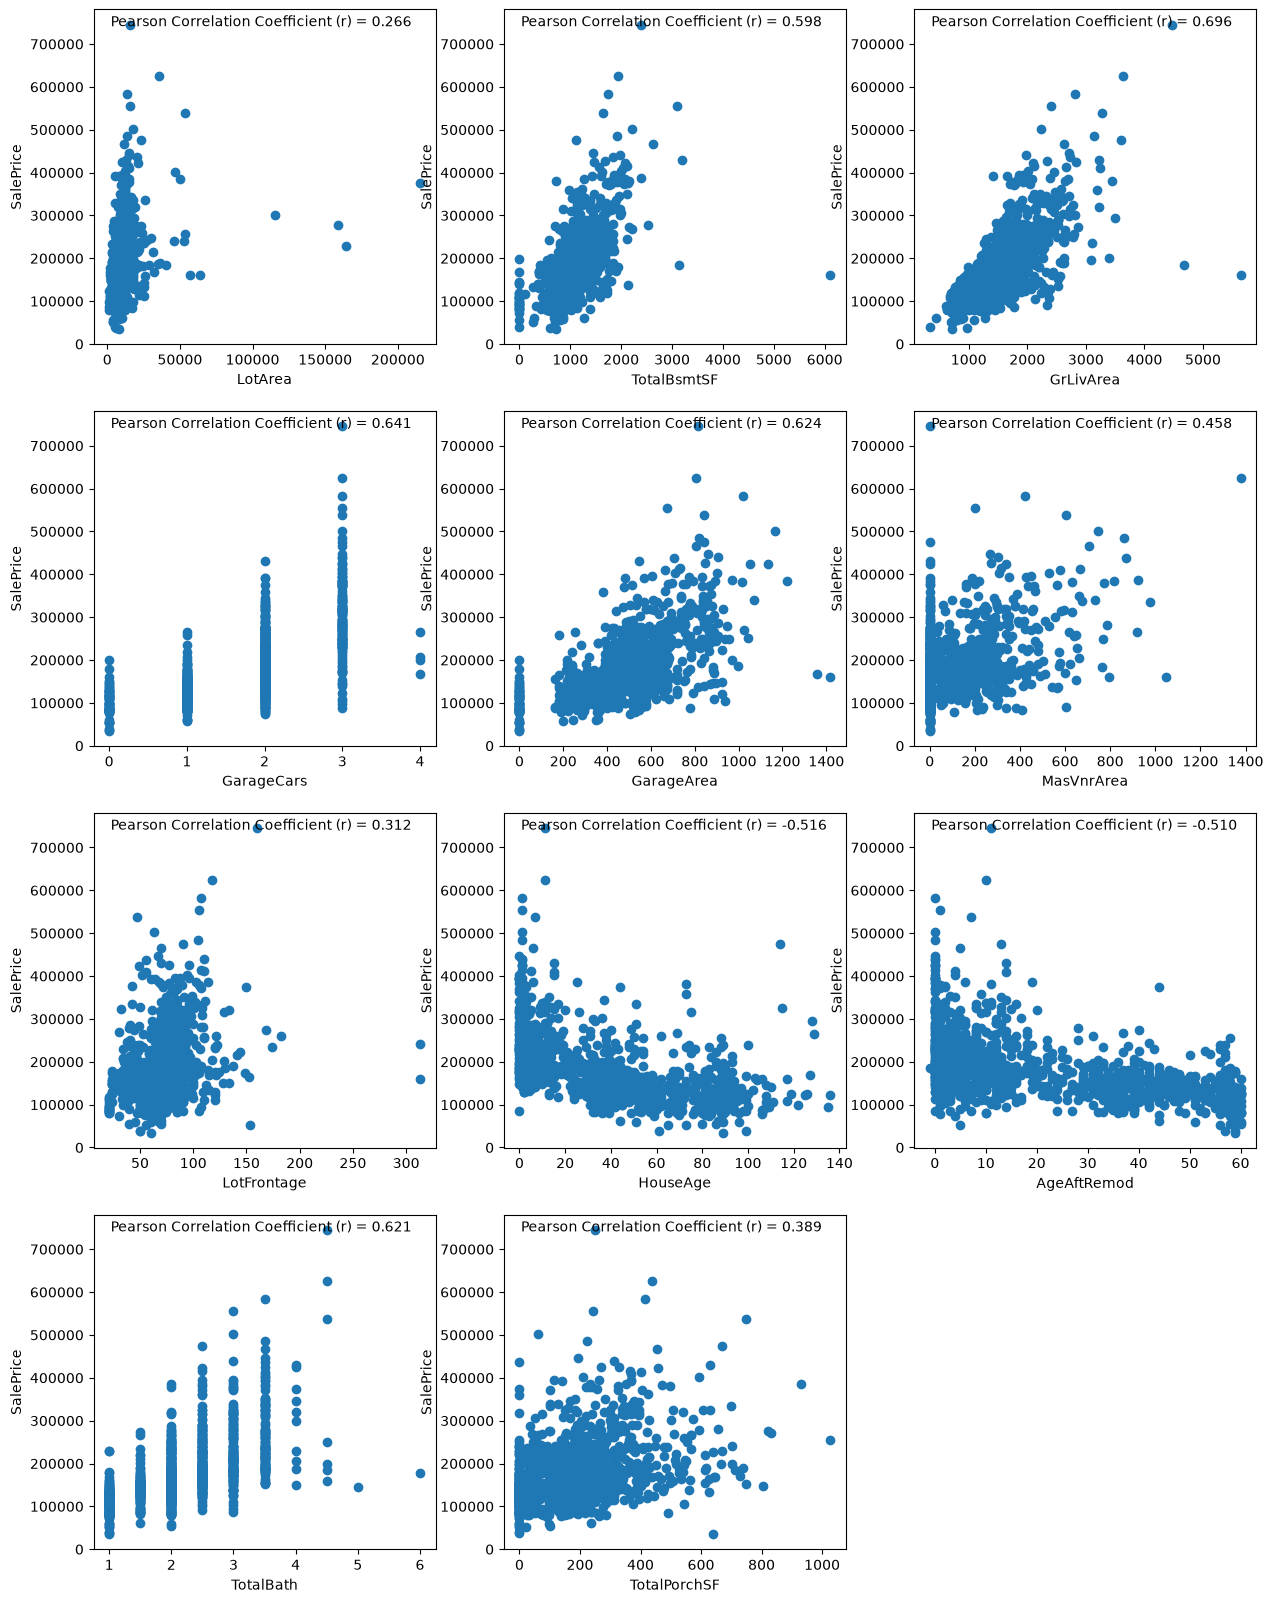

In [20]:
corr_train_df = X_train_imputed_num_df.copy()
corr_train_df[target] = y_train

corr_matrix = corr_train_df.corr()
target_corr = corr_matrix[target]

n_columns = 3
n_rows = (len(num_columns) + n_columns - 1) // n_columns

fig, axes = plt.subplots(n_rows, n_columns, figsize=(15, 5 * n_rows))
axes = axes.flatten()

for i, column in enumerate(num_columns):
    ax = axes[i]
    ax.scatter(X_train_imputed_df[column].values, y_train)
    ax.set_xlabel(column, fontsize=10)
    ax.set_ylabel(target, fontsize=10)

    ax.text(0.05, 0.95, f'Pearson Correlation Coefficient (r) = {target_corr[column]:.3f}', fontsize=10, color='black', transform=ax.transAxes)

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.show()

Let's also see the correlation between numerical features using heatmap visualization.

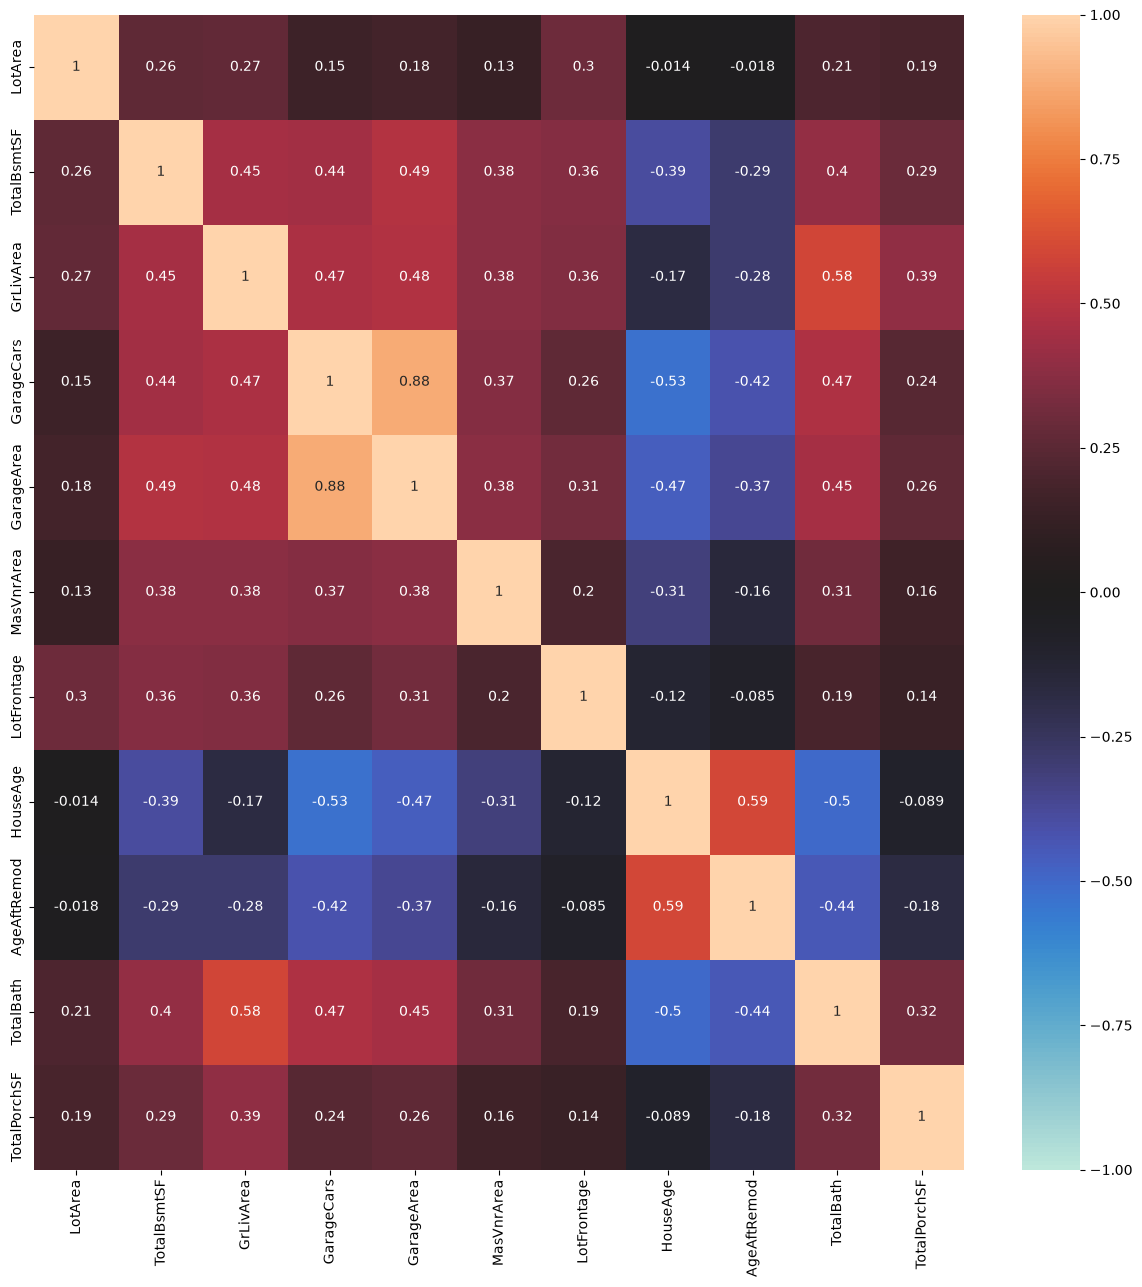

In [21]:
plt.subplots(figsize=(15,15))
sns.heatmap(corr_matrix.iloc[:-1, :-1], vmin=-1, center=0, vmax=1, annot=True)
plt.show()

To select the most predictive features for the linear regression model, a threshold of $|r|> 0.5$ is strictly applied to filter the continuous numerical features. We will get ['TotalBsmtSF', 'GrLivArea', 'GarageCars', 'GarageArea', 'HouseAge', 'AgeAftRemod', 'TotalBath']

However, notice that the heatmap above reveals a severe multicollinearity between GarageCars and GarageArea ($r \approx 0.88$). This strong linear dependency occurs because both features encapsulate the exact same underlying proxy: the physical capacity of the garage. To maintain the full-rank assumption for the linear regression model and avoid variance inflation, one of these features must be eliminated. GarageArea is intentionally preserved because it is a pure continuous numerical variable with higher granularity, whereas GarageCars is dropped to eliminate redundancy.

In [22]:
abs_target_corr = target_corr.abs().drop(target)
selected_num_series = abs_target_corr[abs_target_corr > 0.5]
selected_num = selected_num_series.index.tolist()

# remove GarageCars
selected_num.remove('GarageCars')

print(f'Selected Numerical Features: {selected_num}')
print(f'Number of Selected Numerical Features: {len(selected_num)} Out of {len(num_columns)} Numerical Features.\n')
print('Pearson Correlation Coefficient (r):')
print(selected_num_series.drop('GarageCars'))

Selected Numerical Features: ['TotalBsmtSF', 'GrLivArea', 'GarageArea', 'HouseAge', 'AgeAftRemod', 'TotalBath']
Number of Selected Numerical Features: 6 Out of 11 Numerical Features.

Pearson Correlation Coefficient (r):
TotalBsmtSF    0.597766
GrLivArea      0.695652
GarageArea     0.624139
HouseAge       0.516428
AgeAftRemod    0.509649
TotalBath      0.621280
Name: SalePrice, dtype: float64


#### Categorical Features

Let's also create box plots to visualize the categorical features.

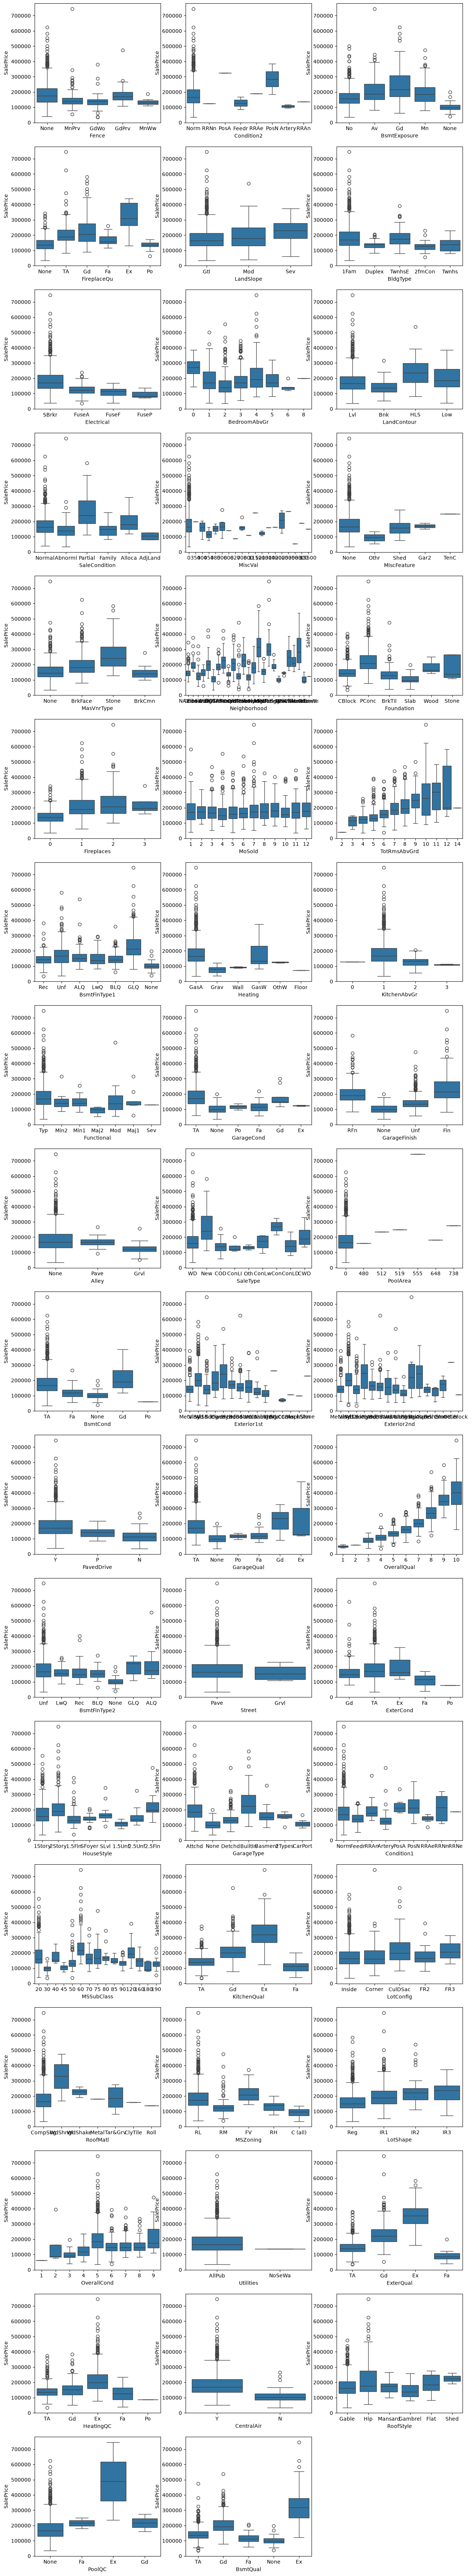

In [23]:
boxplot_train_df = X_train_imputed_cat_df.copy()
boxplot_train_df[target] = y_train

n_columns = 3
n_rows = (len(cat_columns) + n_columns - 1) // n_columns

fig, axes = plt.subplots(n_rows, n_columns, figsize=(15, 5 * n_rows))
axes = axes.flatten()

for i, column in enumerate(cat_columns):
    sns.boxplot(boxplot_train_df, x=column, y=target, ax=axes[i])

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.show()

To determine which categorical and ordinal features hold significant predictive power over the continuous target variable (SalePrice), an Analysis of Variance (**ANOVA**) F-test is employed. Mathematically, ANOVA evaluates whether the mean of the target variable differs significantly across the distinct groups or levels defined by each categorical feature. The statistical hypotheses for this evaluation are formulated as follows:

- Null Hypothesis ($H_0$): The mean SalePrice is identical across all categories of the feature.

- Alternative Hypothesis ($H_1$): At least one category mean is significantly different from the others.

A stringent significance threshold of $\alpha = 0.05$ is applied. Categorical features that yield a $p\text{-value} < 0.05$ allow us to rigorously reject the null hypothesis, confirming that the variance between the category means is statistically significant and not due to random chance. These verified features are selected for downstream dummy encoding and modeling, while non-significant features are discarded to keep the model parsimonious.

A common conceptual question is how a simple comparison of group means can dictate whether a categorical feature is important for a regression model. The mathematical logic lies in the concept of variance explanation.

If we group the house prices (SalePrice) based on a specific categorical feature (for instance, Neighborhood), and we discover that the mean price of houses in Neighborhood A is structurally different from Neighborhood B and Neighborhood C, it demonstrates that knowing the category provides immediate information about the target's magnitude. Mathematically, this implies that the variance between the groups is much larger than the variance within the groups.

In [24]:
from scipy import stats

anova_df = X_train_imputed_cat_df[cat_columns].copy()
anova_df[target] = y_train

anova_results = []

print("----- Running ANOVA Test -----\n")

for column in cat_columns:

    unique_cats = anova_df[column].unique()
    
    grouped_data = [anova_df[anova_df[column] == cat][target].values for cat in unique_cats]

    f_stat, p_val = stats.f_oneway(*grouped_data)
    

    anova_results.append({
        'Feature': column,
        'F_Statistic': f_stat,
        'P_Value': p_val
    })

# convert to DataFrame and sort by F_Statistics in descending order
anova_summary_df = pd.DataFrame(anova_results).sort_values(by='F_Statistic', ascending=False).reset_index(drop=True)

print("Results:\n")
print(anova_summary_df)

# select features with p-value < 0.05
selected_cat = anova_summary_df[anova_summary_df['P_Value'] < 0.05]['Feature'].tolist()
print(f"\nSelected Categorical Features: {selected_cat}\n")
print(f'Number of Selected Categorical Features: {len(selected_cat)} Out of {len(cat_columns)} Categorical Features.')

----- Running ANOVA Test -----

Results:

          Feature  F_Statistic        P_Value
0     KitchenQual   332.403111  7.223574e-156
1       ExterQual   318.566812  5.695797e-151
2     OverallQual   262.806466  1.627739e-272
3        BsmtQual   248.162401  3.875122e-154
4    GarageFinish   171.170540   6.430908e-92
5      Fireplaces   114.707812   4.466366e-65
6     FireplaceQu    92.211841   7.717475e-82
7      CentralAir    89.825144   1.399942e-20
8      MasVnrType    79.691818   6.858075e-47
9       HeatingQC    77.812050   1.597372e-58
10     Foundation    77.154994   6.121416e-70
11     GarageType    64.091698   7.896260e-69
12   Neighborhood    54.116418  2.317899e-169
13   BsmtFinType1    50.857581   1.097677e-55
14   BsmtExposure    46.909362   1.377122e-36
15   TotRmsAbvGrd    40.899515   5.324178e-75
16  SaleCondition    34.303105   9.045336e-33
17     PavedDrive    32.925986   1.230150e-14
18       MSZoning    31.026797   1.412720e-24
19       LotShape    29.314662   2.841

Based on the results above, while applying the standard significance threshold ($\text{p-value} < \alpha$) successfully filters out statistically irrelevant features, it still retains an excessively large number of categorical predictors due to the sample size's high sensitivity. Introducing too many dummy variables post-encoding risks inflating the model's feature space, which leads to structural overfitting and severely degrades the interpretability of a linear estimator.

To enforce a strict parsimonious model constraints, a **Select K-Best** approach is adopted by ranking the features based on their F-Statistic magnitude. Mathematically, the F-statistic represents the ratio of variance between the groups to the variance within the groups ($F = \frac{\text{MS}_{\text{between}}}{\text{MS}_{\text{within}}}$). A larger F-value indicates a clean and distinct separation of target distributions among the categories, yielding a significantly higher signal-to-noise ratio. Therefore, **filtering the top 10** categorical features with the highest F-scores guarantees that we capture the absolute strongest predictors while maintaining a lean and highly stable design matrix.

In [25]:
# reselect features with top 10 F-statistics
selected_cat = anova_summary_df['Feature'].head(10).tolist()
print(f"Selected Top-10 Categorical Features: {selected_cat}\n")

Selected Top-10 Categorical Features: ['KitchenQual', 'ExterQual', 'OverallQual', 'BsmtQual', 'GarageFinish', 'Fireplaces', 'FireplaceQu', 'CentralAir', 'MasVnrType', 'HeatingQC']



### Data Preprocessing Phase 2

Let's apply the selected numerical and categorical features.

In [26]:
X_train_selected_num_df = X_train_imputed_num_df[selected_num]
X_train_selected_cat_df = X_train_imputed_cat_df[selected_cat]

X_test_selected_num_df = X_test_imputed_num_df[selected_num]
X_test_selected_cat_df = X_test_imputed_cat_df[selected_cat]

print(f'X_train_selected_num_df shape: {X_train_selected_num_df.shape}')
print(f'X_train_selected_cat_df shape: {X_train_selected_cat_df.shape}')
print(f'X_test_selected_num_df shape: {X_test_selected_num_df.shape}')
print(f'X_test_selected_cat_df shape: {X_test_selected_cat_df.shape}')

X_train_selected_num_df shape: (1168, 6)
X_train_selected_cat_df shape: (1168, 10)
X_test_selected_num_df shape: (292, 6)
X_test_selected_cat_df shape: (292, 10)


#### Numerical Features Standardization

As observed in the scatter plots for numerical features, the numerical features exhibit vastly different scales and measurement ranges (e.g., GrLivArea ranges in thousands of square feet, whereas TotalBath values range from 1 to 5). Linear regression models are highly sensitive to these scale discrepancies because the optimization algorithm might inadvertently penalize or over-allocate weight to features with larger absolute magnitudes. 

To mitigate this, StandardScaler is applied to transform all numerical features to possess a mean of 0 and a standard deviation of 1 ($\mu = 0, \sigma = 1$).

In [27]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled_num = scaler.fit_transform(X_train_selected_num_df)
X_test_scaled_num = scaler.transform(X_test_selected_num_df)

X_train_scaled_num_df = pd.DataFrame(data=X_train_scaled_num, columns=selected_num)
X_test_scaled_num_df = pd.DataFrame(data=X_test_scaled_num, columns=selected_num)

In [28]:
X_train_scaled_num_df.head()

,TotalBsmtSF,GrLivArea,GarageArea,HouseAge,AgeAftRemod,TotalBath
0,0.572612,-0.407093,-0.863837,0.526141,1.452679,-0.285144
1,-0.596547,0.083170,-0.456264,-0.679464,-0.382563,0.356567
2,-0.603357,-1.395250,-2.257169,1.992419,1.694159,-1.568564
3,-0.750921,0.458975,-1.119755,1.080068,1.645863,0.356567
4,-0.081209,0.312087,-0.797488,1.601411,1.790750,-0.285144


In [29]:
X_test_scaled_num_df.head()

,TotalBsmtSF,GrLivArea,GarageArea,HouseAge,AgeAftRemod,TotalBath
0,-0.006292,-0.876372,-1.006014,0.200302,-0.962113,-0.926854
1,0.910874,2.088099,1.117159,-0.679464,-0.382563,1.639987
2,-0.122072,-0.952678,-0.551048,1.503660,1.790750,-1.568564
3,-0.131153,0.260581,-0.266695,0.721645,1.597567,-0.285144
4,1.267297,0.176644,2.065003,-1.135640,-1.058704,0.998277


#### Categorical Features Encoding

Note that machine learning algorithms can only process number. This means we need to encode the categorical features.

Before, that divide each X_train_selected_cat_df and X_test_selected_cat_df into 2 parts: ordinal categorical features only and nominal categorical features only.

In [30]:
ordinal_cat_columns = ['KitchenQual', 'ExterQual', 'OverallQual', 'BsmtQual', 'FireplaceQu', 'HeatingQC']
nominal_cat_columns = list(set(selected_cat.copy()) - set(ordinal_cat_columns))

X_train_ordinal_cat_df = X_train_selected_cat_df[ordinal_cat_columns]
X_train_nominal_cat_df = X_train_selected_cat_df[nominal_cat_columns]

X_test_ordinal_cat_df = X_test_selected_cat_df[ordinal_cat_columns]
X_test_nominal_cat_df = X_test_selected_cat_df[nominal_cat_columns]

print(f'X_train_ordinal_cat_df shape: {X_train_ordinal_cat_df.shape}')
print(f'X_train_nominal_cat_df shape: {X_train_nominal_cat_df.shape}')
print(f'X_test_ordinal_cat_df shape: {X_test_ordinal_cat_df.shape}')
print(f'X_test_nominal_cat_df shape: {X_test_nominal_cat_df.shape}')

X_train_ordinal_cat_df shape: (1168, 6)
X_train_nominal_cat_df shape: (1168, 4)
X_test_ordinal_cat_df shape: (292, 6)
X_test_nominal_cat_df shape: (292, 4)


##### Ordinal Encoding

In [31]:
print('Value Counts of Ordinal Categorical Features:\n')
for column in X_train_ordinal_cat_df.columns.tolist():
    print(X_train_ordinal_cat_df[column].value_counts())
    print('='*25)

Value Counts of Ordinal Categorical Features:

KitchenQual
TA    589
Gd    470
Ex     77
Fa     32
Name: count, dtype: int64
ExterQual
TA    727
Gd    388
Ex     42
Fa     11
Name: count, dtype: int64
OverallQual
6     311
5     308
7     258
8     135
4      88
9      36
3      16
10     13
1       2
2       1
Name: count, dtype: int64
BsmtQual
TA      521
Gd      493
Ex       97
Fa       29
None     28
Name: count, dtype: int64
FireplaceQu
None    547
Gd      305
TA      252
Fa       27
Ex       21
Po       16
Name: count, dtype: int64
HeatingQC
Ex    583
TA    347
Gd    195
Fa     42
Po      1
Name: count, dtype: int64


Features capturing quality and condition (e.g., ExterQual, KitchenQual) inherently possess a natural mathematical hierarchy. Rather than treating them as nominal text labels, these variables are processed using Ordinal Encoding to translate their qualitative values into a structurally ordered numerical scale (e.g., None $\rightarrow$ 0, Po $\rightarrow$ 1, Fa $\rightarrow$ 2, TA $\rightarrow$ 3, Gd $\rightarrow$ 4, Ex $\rightarrow$ 5).

This encoding scheme preserves the explicit sequence of quality tiers, allowing the linear model to interpret the monotonic progression from poor to excellent directly as a continuous predictive signal.

Ordinal mapping

In [32]:
def ordinal_mapping(x):
    if x == 'None':
        return 0
    elif x == 'Po':
        return 1
    elif x == 'Fa':
        return 2
    elif x == 'TA':
        return 3
    elif x == 'Gd':
        return 4
    elif x == 'Ex':
        return 5
    else:
        return x

X_train_encoded_ordinal_cat_df = X_train_ordinal_cat_df.map(ordinal_mapping)
X_test_encoded_ordinal_cat_df = X_test_ordinal_cat_df.map(ordinal_mapping)

print(f'X_train_encoded_ordinal_cat_df shape: {X_train_encoded_ordinal_cat_df.shape}')
print(f'X_test_encoded_ordinal_cat_df shape: {X_test_encoded_ordinal_cat_df.shape}')


X_train_encoded_ordinal_cat_df shape: (1168, 6)
X_test_encoded_ordinal_cat_df shape: (292, 6)


In [33]:
X_train_encoded_ordinal_cat_df.head()

,KitchenQual,ExterQual,OverallQual,BsmtQual,FireplaceQu,HeatingQC
0,3,3,5,3,0,3
1,3,4,6,4,3,4
2,3,3,5,2,0,4
3,4,3,5,4,3,5
4,4,3,5,3,4,3


In [34]:
X_test_encoded_ordinal_cat_df.head()

,KitchenQual,ExterQual,OverallQual,BsmtQual,FireplaceQu,HeatingQC
0,3,3,6,3,0,3
1,4,4,8,5,3,5
2,3,3,5,3,4,4
3,3,3,6,3,4,5
4,5,4,9,5,5,5


##### One-Hot Encoding

For categorical features that lack any inherent logical ordering or mathematical ranking (such as Foundation or Neighborhood), One-Hot Encoding is implemented. This process converts each nominal category into a set of distinct binary dummy columns ($0$ or $1$).

To prevent the 'dummy variable trap'—which causes perfect multicollinearity within linear estimators—the first category of each feature is dropped (drop='first'). This approach mathematically guarantees a full-rank design matrix while enabling the model to compute isolated intercept shifts for each architectural category.

In [35]:
X_train_encoded_nominal_cat_df = pd.get_dummies(X_train_nominal_cat_df, prefix=nominal_cat_columns, drop_first=True, dtype=int)
X_test_encoded_nominal_cat_df = pd.get_dummies(X_test_nominal_cat_df, prefix=nominal_cat_columns, drop_first=True, dtype=int)

print(f'X_train_encoded_nominal_cat_df shape: {X_train_encoded_nominal_cat_df.shape}')
print(f'X_test_encoded_nominal_cat_df shape: {X_test_encoded_nominal_cat_df.shape}')

X_train_encoded_nominal_cat_df shape: (1168, 10)
X_test_encoded_nominal_cat_df shape: (292, 10)


In [36]:
X_train_encoded_nominal_cat_df.head()

,CentralAir_Y,MasVnrType_BrkFace,MasVnrType_None,MasVnrType_Stone,Fireplaces_1,Fireplaces_2,Fireplaces_3,GarageFinish_None,GarageFinish_RFn,GarageFinish_Unf
0,1,0,1,0,0,0,0,0,1,0
1,1,0,1,0,1,0,0,0,1,0
2,1,0,1,0,0,0,0,1,0,0
3,1,1,0,0,0,1,0,0,0,1
4,1,0,1,0,1,0,0,0,0,1


In [37]:
X_test_encoded_nominal_cat_df.head()

,CentralAir_Y,MasVnrType_BrkFace,MasVnrType_None,MasVnrType_Stone,Fireplaces_1,Fireplaces_2,Fireplaces_3,GarageFinish_None,GarageFinish_RFn,GarageFinish_Unf
0,1,0,1,0,0,0,0,0,1,0
1,1,1,0,0,0,1,0,0,1,0
2,1,0,1,0,1,0,0,0,0,1
3,1,0,1,0,0,1,0,0,0,1
4,1,0,0,1,1,0,0,0,0,0


Concatenate scaled numeric dataframe, encoded ordinal categorical dataframe, and encoded nominal categorical dataframe for each train and test set.

In [38]:
X_train_preprocessed_df = pd.concat([X_train_scaled_num_df, X_train_encoded_ordinal_cat_df, X_train_encoded_nominal_cat_df], axis=1)
X_test_preprocessed_df = pd.concat([X_test_scaled_num_df, X_test_encoded_ordinal_cat_df, X_test_encoded_nominal_cat_df], axis=1)

print(f'X_train_preprocessed_df shape: {X_train_preprocessed_df.shape}')
print(f'X_test_preprocessed_df shape: {X_test_preprocessed_df.shape}')

X_train_preprocessed_df shape: (1168, 22)
X_test_preprocessed_df shape: (292, 22)


In [39]:
X_train_preprocessed_df.head()

,TotalBsmtSF,GrLivArea,GarageArea,HouseAge,AgeAftRemod,TotalBath,KitchenQual,ExterQual,OverallQual,BsmtQual,...,CentralAir_Y,MasVnrType_BrkFace,MasVnrType_None,MasVnrType_Stone,Fireplaces_1,Fireplaces_2,Fireplaces_3,GarageFinish_None,GarageFinish_RFn,GarageFinish_Unf
0,0.572612,-0.407093,-0.863837,0.526141,1.452679,-0.285144,3,3,5,3,...,1,0,1,0,0,0,0,0,1,0
1,-0.596547,0.083170,-0.456264,-0.679464,-0.382563,0.356567,3,4,6,4,...,1,0,1,0,1,0,0,0,1,0
2,-0.603357,-1.395250,-2.257169,1.992419,1.694159,-1.568564,3,3,5,2,...,1,0,1,0,0,0,0,1,0,0
3,-0.750921,0.458975,-1.119755,1.080068,1.645863,0.356567,4,3,5,4,...,1,1,0,0,0,1,0,0,0,1
4,-0.081209,0.312087,-0.797488,1.601411,1.790750,-0.285144,4,3,5,3,...,1,0,1,0,1,0,0,0,0,1


In [40]:
X_test_preprocessed_df.head()

,TotalBsmtSF,GrLivArea,GarageArea,HouseAge,AgeAftRemod,TotalBath,KitchenQual,ExterQual,OverallQual,BsmtQual,...,CentralAir_Y,MasVnrType_BrkFace,MasVnrType_None,MasVnrType_Stone,Fireplaces_1,Fireplaces_2,Fireplaces_3,GarageFinish_None,GarageFinish_RFn,GarageFinish_Unf
0,-0.006292,-0.876372,-1.006014,0.200302,-0.962113,-0.926854,3,3,6,3,...,1,0,1,0,0,0,0,0,1,0
1,0.910874,2.088099,1.117159,-0.679464,-0.382563,1.639987,4,4,8,5,...,1,1,0,0,0,1,0,0,1,0
2,-0.122072,-0.952678,-0.551048,1.503660,1.790750,-1.568564,3,3,5,3,...,1,0,1,0,1,0,0,0,0,1
3,-0.131153,0.260581,-0.266695,0.721645,1.597567,-0.285144,3,3,6,3,...,1,0,1,0,0,1,0,0,0,1
4,1.267297,0.176644,2.065003,-1.135640,-1.058704,0.998277,5,4,9,5,...,1,0,0,1,1,0,0,0,0,0


In [41]:
X_train_preprocessed = X_train_preprocessed_df.values
X_test_preprocessed = X_test_preprocessed_df.values

## Train Model

Now, let's train a linear regression model with X_train_preprocessed and y_train.

In [42]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
lin_reg.fit(X_train_preprocessed, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](22,)","[ 8260.04,20038.39,11274.64,..., 8994.24,-8216.61,-8537.54]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,396.2
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,22
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(22)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](22,)","[89.94,53.07,34.96,..., 3.55, 2.03, 1.77]"


In [43]:
predictors = X_train_preprocessed_df.columns.tolist()
coefficients = lin_reg.coef_
intercept = lin_reg.intercept_

eq = f'{target} = {intercept:.2f}'
i = 1
for coef, pred in zip(coefficients, predictors):
    eq += f' + {coef:.2f}*{pred}'
    if i % 5 == 0:
        eq += '\n'
    i += 1
print(eq)

SalePrice = 396.19 + 8260.04*TotalBsmtSF + 20038.39*GrLivArea + 11274.64*GarageArea + -3033.16*HouseAge + -1192.06*AgeAftRemod
 + 6646.29*TotalBath + 11092.08*KitchenQual + 11627.78*ExterQual + 12488.63*OverallQual + 3959.27*BsmtQual
 + 5189.51*FireplaceQu + -91.17*HeatingQC + 5715.66*CentralAir_Y + 4663.61*MasVnrType_BrkFace + 7223.31*MasVnrType_None
 + 10034.29*MasVnrType_Stone + -9060.35*Fireplaces_1 + 14493.01*Fireplaces_2 + -109233.73*Fireplaces_3 + 8994.24*GarageFinish_None
 + -8216.61*GarageFinish_RFn + -8537.54*GarageFinish_Unf


## Model Evaluation

In [44]:
y_pred = lin_reg.predict(X_test_preprocessed)
print(y_pred)

[125237.87756637 318127.65169004 115179.15202396 189704.9374924
 315374.19539881  85098.6060117  227095.14398652 163833.63012701
  85346.1822527  118351.72027517 159919.19188096 105234.08314025
 108580.53643215 210172.68585276 179258.86775992 122189.91364991
 226841.74088901 106301.46772854 124221.21115974 217063.95368565
 165138.83201738 226019.55234336 205132.46547194 118557.07936313
 230425.23107108 179922.17960739 203847.3542917   86499.17616534
 184031.53759274 215612.9116712  111283.58605479 262794.31860959
 247423.34181674  86356.40304748 272683.44370795 149352.9280821
 151372.71164388 234504.58450411 291831.68282501  67866.46205121
 140110.20560223 256919.10900556 101255.58220467 341213.68029865
 123429.44169886 146224.29300267  98579.4576827  114769.99993277
 354461.47630698 123314.34862556  97822.3059975  231249.7438844
 134001.04355544 309889.8961586  173120.28271276 248776.6149112
 216477.45581803 165217.66596539 157906.09354524  68814.91137739
  39698.48448559 143151.49908

In [45]:
r2 = lin_reg.score(X_test_preprocessed, y_test)

print(f'R^2 = {r2}')

R^2 = 0.8138148685027489


The trained linear regression model achieved a Coefficient of Determination ($R^2$ score) of 0.8138 on the independent test dataset. Mathematically, this signifies that approximately 81.38% of the total variance in house prices (SalePrice) can be successfully explained and predicted by the features selected and engineered within this framework.

Remaining below 20% of unexplained variance is likely attributed to unmeasured stochastic factors or non-linear dynamics. An $R^2$ score above 0.80 indicates a highly robust, generalisable, and statistically stable linear estimator.

To visually inspect the prediction alignment, an overlapping histogram comparing the ground-truth distribution (truth in green) against the model's predictions (prediction in blue) is constructed.

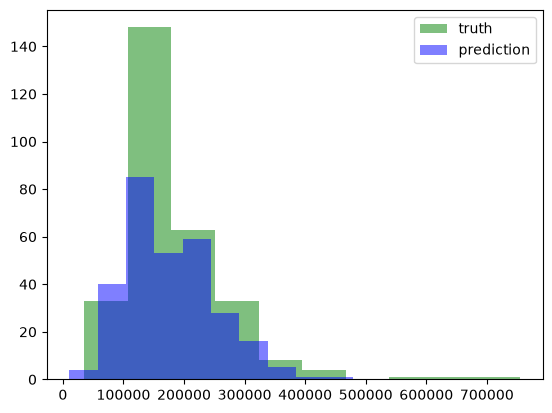

In [46]:
plt.hist(y_test, color='green', alpha=.5)
plt.hist(y_pred, color='blue', alpha=.5)
plt.legend(['truth', 'prediction'], loc='upper right')
plt.show()

The visualization demonstrates that the model captures the central tendency, skewness, and peak density of the dataset exceptionally well, particularly within the mid-tier market segment between $100,000 and $250,000. However, minor distribution variance is visible at the extreme right tail (above $500,000), where the model slightly underestimates high-leverage outliers. This is a characteristic constraint of linear estimators when modeling premium, ultra-luxury property prices that follow exponential pricing dynamics rather than strictly linear traits.